# Notebook 04 — CT Baseline Model
Trains a CNN on CT brain tumor images only. Loads splits from notebook 02. No DICOM processing needed — images are PNG format.
> **Prerequisites:** Run notebook 02 first.

## 1. Mount Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=False)

Mounted at /content/drive


## 2. Download CT Dataset (Skip if Already Done)

In [2]:
import os

if not os.path.exists("/content/ct_tumor/dataset/head ct/no"):
    print("Downloading CT dataset...")
    from google.colab import files
    files.upload()  # upload kaggle.json
    os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
    os.system("cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json")
    os.makedirs("/content/ct_tumor", exist_ok=True)
    os.system("kaggle datasets download -d nipaanjum/head-ct-images-for-classification -p /content/ct_tumor/")
    os.system("unzip /content/ct_tumor/*.zip -d /content/ct_tumor/")
    print("Done!")
else:
    print("Already downloaded, skipping.")

Saving kaggle.json to kaggle.json
Done!


## 3. Imports

In [3]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

IMG_SIZE   = (224, 224)
BATCH_SIZE = 16
EPOCHS     = 50

print("TensorFlow:", tf.__version__)
print("GPU:", len(tf.config.list_physical_devices('GPU')) > 0)

TensorFlow: 2.20.0
GPU: True


## 4. Load Splits from Notebook 02

In [4]:
data = np.load('/content/drive/MyDrive/CT_Tumor/ct_splits.npz', allow_pickle=True)
train_paths = data['train_paths']
val_paths   = data['val_paths']
test_paths  = data['test_paths']
y_train     = data['y_train']
y_val       = data['y_val']
y_test      = data['y_test']

print(f"Train: {len(train_paths)} | Val: {len(val_paths)} | Test: {len(test_paths)}")

Train: 120 | Val: 40 | Test: 40


## 5. Load All Images into Memory

In [5]:
def load_image(path):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, IMG_SIZE)
    return np.expand_dims(img / 255.0, axis=-1)

print("Loading CT images...")
X_train = np.array([load_image(p) for p in train_paths])
X_val   = np.array([load_image(p) for p in val_paths])
X_test  = np.array([load_image(p) for p in test_paths])

print(f"X_train: {X_train.shape} | X_val: {X_val.shape} | X_test: {X_test.shape}")

Loading CT images...
X_train: (120, 224, 224, 1) | X_val: (40, 224, 224, 1) | X_test: (40, 224, 224, 1)


## 6. Build CT Baseline CNN

In [6]:
def build_ct_baseline():
    model = models.Sequential([
        layers.Input(shape=(224, 224, 1)),

        # Block 1
        layers.Conv2D(32, (3,3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2, 2),

        # Block 2
        layers.Conv2D(64, (3,3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2, 2),

        # Block 3
        layers.Conv2D(128, (3,3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2, 2),

        # Block 4 — extra capacity for subtle CT features
        layers.Conv2D(256, (3,3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2, 2),

        layers.GlobalAveragePooling2D(),
        layers.Dense(256, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(1, activation='sigmoid')
    ])
    return model

ct_model = build_ct_baseline()
ct_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)
ct_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 455,809 (1.74 MB)

 Trainable params: 454,849 (1.74 MB)

 Non-trainable params: 960 (3.75 KB)

## 7. Train

In [7]:
early_stop = callbacks.EarlyStopping(
    monitor='val_loss', patience=8, restore_best_weights=True
)
reduce_lr = callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6, verbose=1
)

history = ct_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop, reduce_lr]
)


Epoch 1/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.6083 - loss: 0.6254 - val_accuracy: 0.5000 - val_loss: 0.6920 - learning_rate: 1.0000e-04
Epoch 2/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.7000 - loss: 0.5980 - val_accuracy: 0.5000 - val_loss: 0.6911 - learning_rate: 1.0000e-04
Epoch 3/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 0.6833 - loss: 0.5851 - val_accuracy: 0.5000 - val_loss: 0.6911 - learning_rate: 1.0000e-04
Epoch 4/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.6750 - loss: 0.5522 - val_accuracy: 0.5000 - val_loss: 0.6910 - learning_rate: 1.0000e-04
Epoch 5/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.7500 - loss: 0.5182 - val_accuracy: 0.5000 - val_loss: 0.6903 - learning_rate: 1.0000e-04
Epoch 6/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.7333 - loss: 0.5025 - val_accuracy: 0.5000 - val_loss: 0.6898 - learning_rate: 1.0000e-04
Epoch 7/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.8167 - loss: 0.4594 

## 8. Training Curves

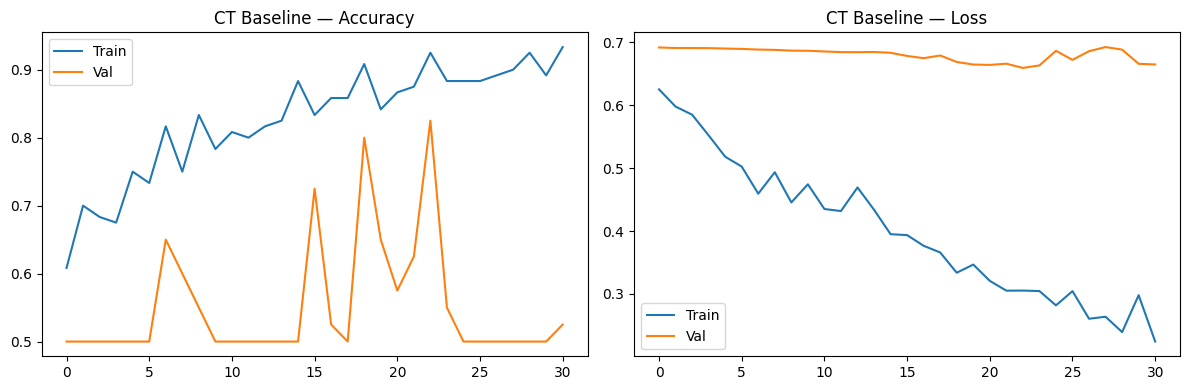

In [8]:
plt.figure(figsize=(12, 4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Val')
plt.title('CT Baseline — Accuracy')
plt.legend()
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.title('CT Baseline — Loss')
plt.legend()
plt.tight_layout()
plt.show()

## 9. Test Set Evaluation

In [9]:
test_probs = ct_model.predict(X_test, batch_size=BATCH_SIZE).flatten()
y_pred     = (test_probs > 0.5).astype(int)

print("--- CT BASELINE: TEST SET RESULTS ---")
print(classification_report(y_test, y_pred, target_names=['Healthy', 'Tumor']))
print(f"ROC-AUC: {roc_auc_score(y_test, test_probs):.4f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 320ms/step
--- CT BASELINE: TEST SET RESULTS ---
              precision    recall  f1-score   support

     Healthy       0.67      1.00      0.80        20
       Tumor       1.00      0.50      0.67        20

    accuracy                           0.75        40
   macro avg       0.83      0.75      0.73        40
weighted avg       0.83      0.75      0.73        40

ROC-AUC: 0.8775


## 10. Confusion Matrix

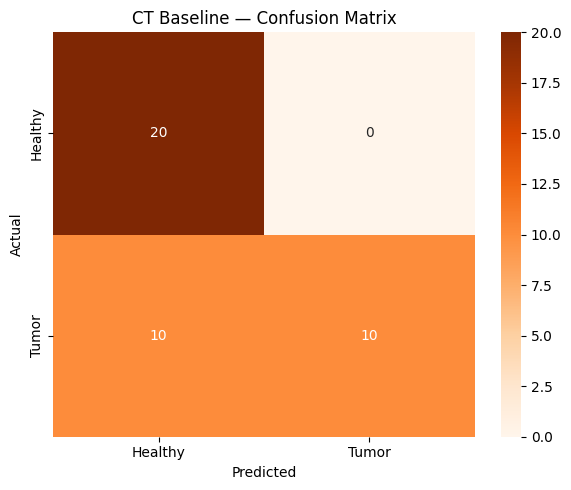

In [10]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Healthy','Tumor'], yticklabels=['Healthy','Tumor'])
plt.title('CT Baseline — Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

## 11. Save Model

In [11]:
ct_model.save("/content/drive/MyDrive/CT_Tumor/ct_baseline.keras")
print("Model saved!")

Model saved!
